# Figure 3: Value of Full Coordination

In [1]:
file ='../Figures'


# import data

import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results':
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes tag in name
            elif tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_econ_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    
    return df

## Import Data

In [2]:
path_part_coord = '../Results/Staged/Partial_coordination/'
path_full_coord = '../Results/Staged/Full_coordination/'
path_no_coord = '../Results/Staged/No_coordination/'

path_NSPC = '../Results/Non_Staged/Partial_coordination/'
path_NSFC = '../Results/Non_Staged/Full_coordination/'
path_NSNNC = '../Results/Non_Staged/No_coordination/'

path_SFC_10 = '../Results/Staged/Full_coordination_10_yr/'
path_SFC_20 = '../Results/Staged/Full_coordination_20_yr/'

dfs_part_coord = create_dataframe(path_part_coord, 'results')
dfs_full_coord = create_dataframe(path_full_coord, 'results')
dfs_no_coord = create_dataframe(path_no_coord, 'results')

dfs_NSPC = create_dataframe(path_NSPC, 'results')
dfs_NSFC = create_dataframe(path_NSFC, 'results')
dfs_NSNNC = create_dataframe(path_NSNNC, 'results')

dfs_SFC_10 = create_dataframe(path_SFC_10, 'results')
dfs_SFC_20 = create_dataframe(path_SFC_20, 'results')

## Plot upgrade operation schedule for each WWTP

In [3]:
# Schedule of individual WWTPs

import plotly.express as px

WWTPs = list(dfs_part_coord.keys())
upgrades = ['SS', 'L2', 'L2upg3', 'L3']

for WWTP in WWTPs:
    df = create_df(WWTP, dfs_part_coord)
    start_date = df.Datetime[0]
    Schedule = pd.DataFrame(columns=['Upgrade', 'Start', 'Finish', 'Status'])
    
    for L in upgrades:
        Build_time = np.array(df.Datetime[df[L + '_z']> 0].astype(str).reset_index(drop=True))
        Op_time = np.array(df.Datetime[df[L + '_status']> 0].astype(str).reset_index(drop=True))
        if len(Build_time) > 0:
            B_start = Build_time[0]
            B_end = Build_time[-1]
            Schedule.loc[L + '_build'] = [L, B_start, B_end, 'Build']
        else:
            Schedule.loc[L + '_build'] = [L, start_date, start_date, 'Build']
        if len(Op_time) > 0:
            Op_start = Op_time[0]
            Op_end = Op_time[-1]
            Schedule.loc[L + '_op'] = [L, Op_start, Op_end, 'Operate']
        else:
            Schedule.loc[L + '_op'] = [L, start_date, start_date, 'Operate']

In [4]:
import plotly.express as px
custom_colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
custom_pattern = {'L3': '/', 'L2': '', 'SS': '', 'L2upg3': '\\'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 9
leg_size = 8
line_wid = 0.75
bord_wid = 2

def create_schedule(dfs, Title, lab):
    WWTPs = sorted(list(dfs.keys()))
    upgrades = ['SS', 'L2', 'L2upg3', 'L3']

    Schedule = pd.DataFrame(columns=['WWTP','Upgrade', 'Start', 'Finish', 'Status'])

    for WWTP in WWTPs:
        df = create_df(WWTP, dfs)
        start_date = df.Datetime[0]
        for L in upgrades:
            Build_time = np.array(df.Datetime[df[L + '_z']> 0].astype(str).reset_index(drop=True))
            Op_time = np.array(df.Datetime[df[L + '_status']> 0].astype(str).reset_index(drop=True))
            if len(Build_time) > 0:
                B_start = Build_time[0]
                B_end = Build_time[-1]
                Schedule.loc[WWTP + '_' + L + '_build'] = [WWTP, L, B_start, B_end, 'Build']
            else:
                Schedule.loc[WWTP + '_' +L + '_build'] = [WWTP, L, start_date, start_date, 'Build']
            if len(Op_time) > 0:
                Op_start = Op_time[0]
                Op_end = Op_time[-1]
                Schedule.loc[WWTP + '_' + L + '_op'] = [WWTP, L, Op_start, Op_end, 'Operate']
            else:
                Schedule.loc[WWTP + '_' +L + '_op'] = [WWTP, L, start_date, start_date, 'Operate']
                
    fig = px.timeline(Schedule[Schedule.Status == 'Operate'], x_start="Start", x_end="Finish", y="WWTP", 
                      color="Upgrade", color_discrete_map=custom_colors, pattern_shape="Upgrade", pattern_shape_map=custom_pattern)
    tickvals = pd.date_range(start="2025-01-01", end="2055-01-01", freq='5YS')  # 5-year frequency
    if pd.Timestamp("2054-01-01") not in tickvals:
        tickvals = tickvals.append(pd.DatetimeIndex(["2055-01-01"]))
    
    fig.update_xaxes(
        tickvals=tickvals,
        tickformat="%Y",  # Display years only
        title="",
        tickfont=dict(family="Helvetica", size=leg_size, color="black"),
        ticks="outside"
    )

    fig.update_yaxes(
        tickfont=dict(family="Helvetica", size=leg_size, color="black"),
        showticklabels=True,
        ticksuffix = "  "
    )


    fig.update_layout(
    barmode='group', legend=dict(font=dict(family="Helvetica", size=leg_size, color="black")),
    plot_bgcolor="white",  # Plot area background
    paper_bgcolor="white",  # Entire figure background
    #margin=dict(l=50, r=5, t=30, b=10),  # Space for black border
    margin=dict(l=0, r=10, t=30, b=0),
    yaxis_title="",
    xaxis=dict(gridcolor="white"),
    shapes=[
        dict(
            type="rect",  # Rectangle shape
            xref="paper", yref="paper",  # Use relative coordinates
            x0=0, x1=1, y0=0, y1=1,     # Enclose the entire plot area
            line=dict(color="black", width=1)  # Black border with specified width
        )
    ],
    title=dict(text=Title, font=dict(family="Helvetica", size=lab_size, color = 'black'), x=0.5, xanchor="center"),
    )   

    fig.update_yaxes(tickfont=dict(family="Helvetica", size=lab_size))
    #fig.add_annotation(text="<b>i</b>", xref="paper", yref="paper", x=0.05, y=0.95, xanchor="left", yanchor="top", showarrow=False, font=dict(family="Helvetica", size=lab_size, color="black"))
    fig.add_annotation(text="<b>"+ lab +"</b>", xref="paper", yref="paper", x=0.05, y=0.95, xanchor="left", yanchor="top", showarrow=False, font=dict(family="Helvetica", size=lab_size, color="black"))

    return Schedule, fig

In [5]:
import plotly.io as pio

Schedule_full, fig = create_schedule(dfs_full_coord, 'S-FC: Staged, Fully coordinated (starting in 2025)', 'ii')
pio.write_image(fig, file + '/Fig_3c_ii.svg', width=400/1.2, height=250/1.2)

Schedule_no, fig = create_schedule(dfs_no_coord, 'S-NC: Staged, Non-coordinated\n S-PC: Staged, Partially coordinated','i')
pio.write_image(fig, file + '/Fig_3c_i.svg', width=400/1.2, height=250/1.2)


## Create plots of constructed schedule 

In [6]:
import plotly.express as px
custom_colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
custom_pattern = {'L3': '/', 'L2': '', 'SS': '', 'L2upg3': '\\'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 9
leg_size = 8
line_wid = 0.75
bord_wid = 2

def create_schedule_built_infrastructure(dfs, Title, lab):
    WWTPs = sorted(list(dfs.keys()))
    upgrades = ['SS', 'L2', 'L2upg3', 'L3']

    Schedule = pd.DataFrame(columns=['WWTP','Upgrade', 'Start', 'Finish', 'Status'])

    for WWTP in WWTPs:
        df = create_df(WWTP, dfs)
        start_date = df.Datetime[0]
        for L in upgrades:
            Build_time = np.array(df.Datetime[df[L + '_z']> 0].astype(str).reset_index(drop=True))
            Op_time = np.array(df.Datetime[df[L + '_status']> 0].astype(str).reset_index(drop=True))
            if len(Build_time) > 0:
                B_start = str(pd.to_datetime(Build_time[0]) + pd.DateOffset(years=5))
                B_end = Build_time[-1]
                Schedule.loc[WWTP + '_' + L + '_build'] = [WWTP, L, B_start, B_end, 'Build']
            else:
                Schedule.loc[WWTP + '_' +L + '_build'] = [WWTP, L, start_date, start_date, 'Build']
            if len(Op_time) > 0:
                Op_start = Op_time[0]
                Op_end = Op_time[-1]
                Schedule.loc[WWTP + '_' + L + '_op'] = [WWTP, L, Op_start, Op_end, 'Operate']
            else:
                Schedule.loc[WWTP + '_' +L + '_op'] = [WWTP, L, start_date, start_date, 'Operate']
                
    fig = px.timeline(Schedule[Schedule.Status == 'Build'], x_start="Start", x_end="Finish", y="WWTP", 
                      color="Upgrade", color_discrete_map=custom_colors, pattern_shape="Upgrade", pattern_shape_map=custom_pattern)
    tickvals = pd.date_range(start="2024-01-01", end="2054-01-01", freq='5YS')  # 5-year frequency
    if pd.Timestamp("2054-01-01") not in tickvals:
        tickvals = tickvals.append(pd.DatetimeIndex(["2054-01-01"]))
    
    fig.update_xaxes(
        tickvals=tickvals,
        tickformat="%Y",  # Display years only
        title="",
        tickfont=dict(family="Helvetica", size=leg_size, color="black"),
        ticks="outside"
    )

    fig.update_yaxes(
        tickfont=dict(family="Helvetica", size=lab_size, color="black"),
        showticklabels=True,
        ticksuffix = "  "
    )


    fig.update_layout(
    barmode='group', legend=dict(font=dict(family="Helvetica", size=lab_size, color="black")),
    plot_bgcolor="white",  # Plot area background
    paper_bgcolor="white",  # Entire figure background
    #margin=dict(l=50, r=5, t=30, b=10),  # Space for black border
    margin=dict(l=0, r=10, t=30, b=0),
    yaxis_title="",
    xaxis=dict(gridcolor="white"),
    shapes=[
        dict(
            type="rect",  # Rectangle shape
            xref="paper", yref="paper",  # Use relative coordinates
            x0=0, x1=1, y0=0, y1=1,     # Enclose the entire plot area
            line=dict(color="black", width=1)  # Black border with specified width
        )
    ],
    title=dict(text=Title, font=dict(family="Helvetica", size=lab_size, color = 'black'), x=0.5, xanchor="center"),
    )   

    fig.update_yaxes(tickfont=dict(family="Helvetica", size=lab_size))
    fig.add_annotation(text="<b>"+ lab +"</b>", xref="paper", yref="paper", x=0.05, y=0.95, xanchor="left", yanchor="top", showarrow=False, font=dict(family="Helvetica", size=lab_size, color="black"))

    return Schedule, fig

In [7]:
# SI Figures
import plotly.io as pio
Schedule_full_coord, fig = create_schedule_built_infrastructure(dfs_full_coord, '(a) S-FC: Staged, Fully coordinated (Starting in 2025)', '')
pio.write_image(fig, file + '/SI/S6a.svg', width=500/1.2, height=250/1.2)

Schedule_SFC_10, fig = create_schedule_built_infrastructure(dfs_SFC_10, '(b) S-FC: Staged, Fully coordinated (starting in 2035)', '')
pio.write_image(fig, file + '/SI/S6b.svg', width=500/1.2, height=250/1.2)

Schedule_SFC_20, fig = create_schedule_built_infrastructure(dfs_SFC_20, '(c) S-FC: Staged, Fully coordinated (starting in 2045)', '')
pio.write_image(fig, file + '/SI/S6c.svg', width=500/1.2, height=250/1.2)

In [8]:
# SI Figures
import plotly.io as pio
Schedule_NSNC, fig = create_schedule_built_infrastructure(dfs_NSNNC, '(a) NS-NC: Non-staged, Non-coordinated', '')
pio.write_image(fig, file + '/SI/S7a.svg', width=500/1.2, height=250/1.2)

Schedule_NSPC, fig = create_schedule_built_infrastructure(dfs_NSPC, '(b) NS-PC: Non-staged, Partially coordinated', '')
pio.write_image(fig, file + '/SI/S7b.svg', width=500/1.2, height=250/1.2)

Schedule_NSFC, fig = create_schedule_built_infrastructure(dfs_NSFC, '(c) NS-FC: Non-staged, Fully coordinated', '')
pio.write_image(fig, file + '/SI/S7c.svg', width=500/1.2, height=250/1.2)


## Fig 3e: Value of coordination

# Plotting all eight cases on one bar graph

In [9]:
# import staged data
path_SNC = '../Results/Staged/No_coordination_summary.csv'
path_SPC = '../Results/Staged/Partial_coordination_summary.csv'
path_SFC = '../Results/Staged/Full_coordination_summary.csv'
path_SFC_10 = '../Results/Staged/Full_coordination_10_yr_summary.csv'
path_SFC_20 = '../Results/Staged/Full_coordination_20_yr_summary.csv'

df_SNC = pd.read_csv(path_SNC)
df_SPC = pd.read_csv(path_SPC)
df_SFC = pd.read_csv(path_SFC)
df_SFC_10 = pd.read_csv(path_SFC_10)
df_SFC_20 = pd.read_csv(path_SFC_20)


ind_stg = ['Case 2:\nNot coordinated', 'Case 4:\nPartially coordinated', 'Case 6:\nFully coordinated', 'Case 7:\nFully coordinated (10 yr)', 'Case 8:\nFully coordinated (20 yr)']
total_cost_stg = [df_SNC[df_SNC['Abbreviation'] == 'Total']['Total_cost'].values[0], df_SPC[df_SPC['Abbreviation'] == 'Total']['Total_cost'].values[0], df_SFC[df_SFC['Abbreviation'] == 'Total']['Total_cost'].values[0], df_SFC_10[df_SFC_10['Abbreviation'] == 'Total']['Total_cost'].values[0], df_SFC_20[df_SFC_20['Abbreviation'] == 'Total']['Total_cost'].values[0]]
opex_cost_stg = [df_SNC[df_SNC['Abbreviation'] == 'Total']['Total_opex'].values[0], df_SPC[df_SPC['Abbreviation'] == 'Total']['Total_opex'].values[0], df_SFC[df_SFC['Abbreviation'] == 'Total']['Total_opex'].values[0], df_SFC_10[df_SFC_10['Abbreviation'] == 'Total']['Total_opex'].values[0], df_SFC_20[df_SFC_20['Abbreviation'] == 'Total']['Total_opex'].values[0]]
capex_cost_stg = [df_SNC[df_SNC['Abbreviation'] == 'Total']['Total_capex'].values[0], df_SPC[df_SPC['Abbreviation'] == 'Total']['Total_capex'].values[0], df_SFC[df_SFC['Abbreviation'] == 'Total']['Total_capex'].values[0], df_SFC_10[df_SFC_10['Abbreviation'] == 'Total']['Total_capex'].values[0], df_SFC_20[df_SFC_20['Abbreviation'] == 'Total']['Total_capex'].values[0]]

# import non-staged data
path_NSNC = '../Results/Non_Staged/No_coordination_summary.csv'
path_NSPC = '../Results/Non_Staged/Partial_coordination_summary.csv'
path_NSFC = '../Results/Non_Staged/Full_coordination_summary.csv'


df_NSNC = pd.read_csv(path_NSNC)
df_NSPC = pd.read_csv(path_NSPC)
df_NSFC = pd.read_csv(path_NSFC)

ind_nstg = ['Case 1:\nNo coordination', 'Case 3:\nPartial coordination', 'Case 5:\nFull coordination']
total_cost_nstg = [df_NSNC[df_NSNC['Abbreviation'] == 'Total']['Total_cost'].values[0], df_NSPC[df_NSPC['Abbreviation'] == 'Total']['Total_cost'].values[0], df_NSFC[df_NSFC['Abbreviation'] == 'Total']['Total_cost'].values[0]]
opex_cost_nstg = [df_NSNC[df_NSNC['Abbreviation'] == 'Total']['Total_opex'].values[0], df_NSPC[df_NSPC['Abbreviation'] == 'Total']['Total_opex'].values[0], df_NSFC[df_NSFC['Abbreviation'] == 'Total']['Total_opex'].values[0]]
capex_cost_nstg = [df_NSNC[df_NSNC['Abbreviation'] == 'Total']['Total_capex'].values[0], df_NSPC[df_NSPC['Abbreviation'] == 'Total']['Total_capex'].values[0], df_NSFC[df_NSFC['Abbreviation'] == 'Total']['Total_capex'].values[0]]


total_cost = [total_cost_nstg[0], total_cost_stg[0], total_cost_nstg[1], total_cost_stg[1], total_cost_nstg[2], total_cost_stg[2], total_cost_stg[3], total_cost_stg[4]]

In [10]:
ind_title = ['Non-coordinated', 'Partially coordinated', 'Fully coordinated']
ind = ['NS-NC', 'S-NC', 'NS-PC', 'S-PC','NS-FC', 'S-FC\n(starting in\n2025)', 'S-FC\n(starting in\n2035)', 'S-FC\n(starting in\n2045)']
total_cost = [total_cost_nstg[0], total_cost_stg[0],total_cost_nstg[1], total_cost_stg[1], total_cost_nstg[2], total_cost_stg[2], total_cost_stg[3], total_cost_stg[4]]
opex_cost = [opex_cost_nstg[0], opex_cost_stg[0],opex_cost_nstg[1], opex_cost_stg[1],opex_cost_nstg[2], opex_cost_stg[2], opex_cost_stg[3], opex_cost_stg[4]]
capex_cost = [capex_cost_nstg[0], capex_cost_stg[0], capex_cost_nstg[1], capex_cost_stg[1],capex_cost_nstg[2], capex_cost_stg[2], capex_cost_stg[3], capex_cost_stg[4]]

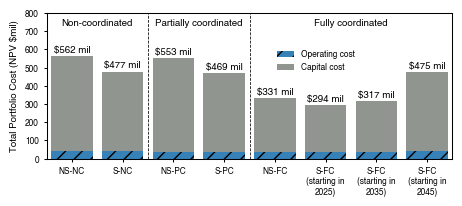

In [11]:
colors = ['#909590', '#3581B8']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2


#fig, axs = plt.subplots(1, 1, figsize=(180/25.4, 55/25.4))
fig, axs = plt.subplots(1, 1, figsize=(120/25.4, 55/25.4))


plt.bar(ind, opex_cost, label = 'Operating cost' , color=colors[1],  hatch = '//', width = 0.82)
bars = plt.bar(ind, capex_cost, label = 'Capital cost' , color= colors[0], bottom = opex_cost, width = 0.82)

for i,bar in enumerate(bars):
    yval = total_cost[i]
    #plt.text(bar.get_x() + bar.get_width()/2.0, yval - yval/2, '$' + str(int(round(yval,0))) + ' mil', va='bottom', ha='center', color='white', fontsize=lab_size, font='Helvetica', fontweight='bold')
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10, '$' + str(int(round(yval,0))) + ' mil', va='bottom', ha='center', color='black', fontsize=lab_size, font='Helvetica', fontweight='bold')


# Adding vertical lines
for x in [2, 4]:  # Add lines at positions 2 and 4
    plt.axvline(x=x - 0.5, color='black', linewidth=line_wid*0.75, linestyle='--')

title_positions = [1, 3, 6]  # Positions for the titles (center of each group)
for pos, title in zip(title_positions, ind_title):
    plt.text(pos-0.5, 770, title, ha='center', va='top', color='black', fontsize=lab_size, font='Helvetica')



plt.ylabel('Total Portfolio Cost (NPV $mil)', **hfont)
#change limits on axis
plt.yticks(**hfont_ticks)
plt.xticks(**hfont)

#change font of legend to helvetica
plt.legend(prop={'family':'Helvetica', 'size':leg_size}, frameon=False, bbox_to_anchor=(0.55, 0.8), ncol=1)
plt.ylim(0, 800)
plt.xlim(-0.5, 7.5)

axs.tick_params(axis='both', which='major', labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid, labelsize=leg_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

plt.tight_layout()


fig.savefig(file + "/Fig_3e.svg", format="svg", dpi=300)

Value of full coordination: 267
Value of staged coordination: 37
Value of coordination: 183
Value added: 48


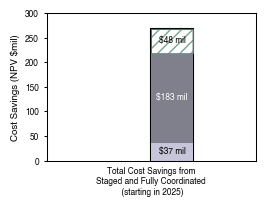

In [12]:
#colors = ['#8EC7D2', '#0D6986', '#07485B']
colors = ['#C6C5D9', '#80808C', 'white']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2


fig, axs = plt.subplots(1, 1, figsize=(70/25.4, 55/25.4))


# Calculate value of staged coordination
val_full = -(total_cost[5] - total_cost[0])
val_stg = -(total_cost[5] - total_cost[4])
val_coord = -(total_cost[5] - total_cost[1])
val_added = val_full - val_stg - val_coord

values = [val_stg, val_coord, val_added]

print('Value of full coordination:', round(val_full))
print('Value of staged coordination:', round(val_stg))
print('Value of coordination:', round(val_coord))
print('Value added:', round(val_added))

ind = [0]
ind_2 = [1]
wid = 0.5

plt.bar(ind, val_full , color='white', edgecolor = "black", width = wid, alpha = 1, linewidth = 1.5)
plt.bar(ind, val_stg, label = 'Only Staged', color=colors[0], width = wid)
plt.bar(ind, val_coord, label = 'Only FC' , color= colors[1], bottom = val_stg, width = wid)
bars = plt.bar(ind, val_added, label = 'Added Value' , color= colors[2], bottom = val_coord + val_stg, width = wid, hatch = '///', edgecolor = '#468966', linewidth = 0.5, alpha = 0.75)


#plt.ylim(0, 300)
plt.ylim(0, 300)
plt.xlim(-1.5, 1)


plt.ylabel('Cost Savings (NPV $mil)', **hfont)
#change limits on axis
plt.yticks(**hfont_ticks)
plt.xticks(**hfont)
plt.yticks(np.arange(0, 301, 50))
plt.xticks([])

#change font of legend to helvetica
#plt.legend(prop={'family':'Helvetica', 'size':leg_size}, frameon=False, ncol=2, loc = 'upper left')


text_positions = [val_stg/2, val_stg + val_coord/2, val_stg+val_coord+val_added/2]  # Positions for the titles (center of each group)
colors_2 = ['black', 'white', 'black']
text = ['$'+str(round(val_stg)) + ' mil', '$'+str(round(val_coord)) + ' mil', '$'+str(round(val_added))+ ' mil']
i=0
for pos, text in zip(text_positions, text):
    plt.text(0, pos+10, text, ha='center', va='top', color=colors_2[i], fontsize=leg_size, font='Helvetica', fontweight='bold')
    i+=1



axs.tick_params(axis='both', which='major', labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid, labelsize=leg_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

plt.xlabel('Total Cost Savings from\nStaged and Fully Coordinated\n (starting in 2025)', **hfont_ticks)
plt.tight_layout()

#change size of figure
fig = plt.gcf()
fig.savefig(file + "/Fig_3f.svg", format="svg", dpi=300)
